### A worked example behind Figure 1
Figure 1 is the proof of principle for the Random Probe (RP) estimator. It is easy to estiamte haplotype frequencies, $D$, and $r^2$ for a pair of biallelic loci, given phased data, as the four haplotype frequencies can be directly observed (with error, of course). This is also the mle under multinomial sampling. In short, the input dataset is a set of four haplotype counts. 

The mle of $r^2$ can be found direcly with the mle haplotype frequencies (invariant principle), but it is severly biased upward. Another method is the RG estimator (by Ragsdale and Gravel, 2020), which uses the ratio of the unbiased estimators for the numerator and denominator. It is less biased, but strictly speaking we cannot call it an unbiased estimator (note: neither can we call RP unbiased. Do unbiased LD estiamtors exist?). 

Then we have our new estimator RP which needs two things: First we need a set of randomly generated probe loci (20,000 of them, say), and they should be highly polymorphic. Second we calculate the $r^2$ between each of the probe locus with our two focal loci, via an existing (can be biased) LD estimator. At the end we have 20,000 pairs of $r^2$. Finally we find the Pearson correlation coefficient between these 20,000 pairs and this is our RP estimate.  

Below is an example demontrating its usage, given the true underlying $D$, marginal allele frequencies, and sample size. We wrap everything into the function <code>f()</code>. This function will first calculate the true (population) $r^2$ from the input arguments (two marginal allele frequencies and $D$). 

Then it takes one set of sample with multinomial error at a time (given diploid sample size $s$), then re-estimates LD via the four routines: mle, RP+mle, RG, RP+RG. For RP, 20,000 probe loci are used. The whole process is repeated 5,000 times to generate 5,000 independent sets of estiamtes. The bias^2, variance, MSE of the estimators can be evaluated through these values. Note that $MSE=variance+bias^2$. 

Three scenarios were examined as explained in the main text: 1) highly polymorphic loci in LE, 2) reasonably polymorphic loci in LD, 3) skewed allele frequency in LD. The same cases were examined by RG as well. 

To reproduce Figure 1, you'll need to repeat this notebook across different values of $s$, and further across different underlying true $r^2$. 

Note that some functions, such as those estimators, are written in C for speed (compiled as a shared object, callable from R). See separate .C file. The formulae for RG come from the main text of its original publication. 

In [1]:
require(compiler)
enableJIT(3)

dyn.load('../cpp/unbiased_r2_2.dll')

Loading required package: compiler



[1] 3

In [2]:
# SOME INNER FUNCTIONS
# INITIALSE A POPULATION
initialise<-function(N, p1=0.5, p2=0.5, D=0)
{
    y<-.Call('initialise2', as.integer(N), as.double(p1), as.double(p2), as.double(D))
    id<-sample(1:(2*N))
    return(y[id,])
}
# SAMPLE PHASED, WITHOUT REPLACEMENT
sample_phased<-function(y, s=50)
{
    N<-nrow(y)/2
    temp<-sample(1:N, size=s, replace=F)-1
    z<-.Call('sample_phased', y, as.integer(temp))
    return(z)
}

In [7]:
# WRAP EVERYTHING TOGETHER
f<-function(p1=0.4, p2=0.6, D=0.1, s=50)
{
    # TRUE POPULATION AND TRUE r2
    y<-initialise(N=20000, p1=p1, p2=p2, D=D)
    true_r2<-.Call('mle_phased', as.raw(y[,1]), as.raw(y[,2]))
    # SIM SETTINGS
    times<-5000
    ncpu<-8; mode(ncpu)<-'integer'; 
    # EMPTY VECTORS TO STORE RESULTS
    r2_mle<-rep(NA, times)
    r2_mle_block<-rep(NA, times)
    r2_RG<-rep(NA, times)
    r2_RG_block<-rep(NA, times)
    #
    for (i in 1:times)
    {
        # SAMPLING
        temp<-sample_phased(y, s=s)
        # GENERATE THE DUMMY PROBE LOCI
        z<-.Call('white_noise_phased', as.integer(s), as.double(runif(20000, 0.4, 0.6)))
        # RE-ESTIMATE r^2 WITH THE FOUR ESTIMATORS
        r2_mle[i]<-.Call('mle_phased', as.raw(temp[,1]), as.raw(temp[,2]))
        r2_mle_block[i]<-.Call('mle_phased_block', as.raw(temp[,1]), as.raw(temp[,2]), z, ncpu)
        r2_RG[i]<-.Call('RG_phased', as.raw(temp[,1]), as.raw(temp[,2]))
        r2_RG_block[i]<-.Call('RG_phased_block', as.raw(temp[,1]), as.raw(temp[,2]), z, ncpu)
    }
    # RETURN OUTPUTS
    return(list(s=s, true_r2=true_r2, times=times, 
                r2_mle=r2_mle, r2_mle_block=r2_mle_block, r2_RG=r2_RG, r2_RG_block=r2_RG_block))
}

In [13]:
# LET'S RUN IT
y<-f(p1=0.4, p2=0.05, D=0, s=50)

In [14]:
# TRUE POPULATION r^2
y$true_r2

[1] 0

In [15]:
# OUT ESTIMATE
mean(y$r2_mle, na.rm=T)
mean(y$r2_mle_block, na.rm=T)
mean(y$r2_RG, na.rm=T)
mean(y$r2_RG_block, na.rm=T)

[1] 0.009958621

[1] -0.0002881976

[1] -0.0001184047

[1] -0.0002779348

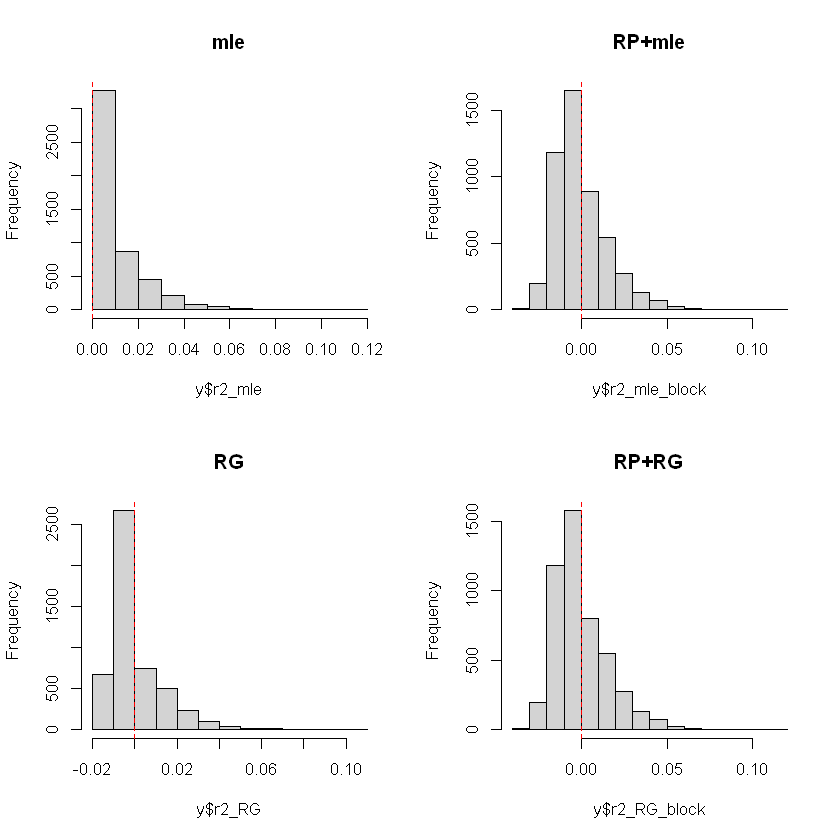

In [16]:
par(mfrow=c(2,2))
hist(y$r2_mle, main='mle')
abline(v=y$true_r2, col='red', lty=2)
hist(y$r2_mle_block, main='RP+mle')
abline(v=y$true_r2, col='red', lty=2)
hist(y$r2_RG, main='RG')
abline(v=y$true_r2, col='red', lty=2)
hist(y$r2_RG_block, main='RP+RG')
abline(v=y$true_r2, col='red', lty=2)

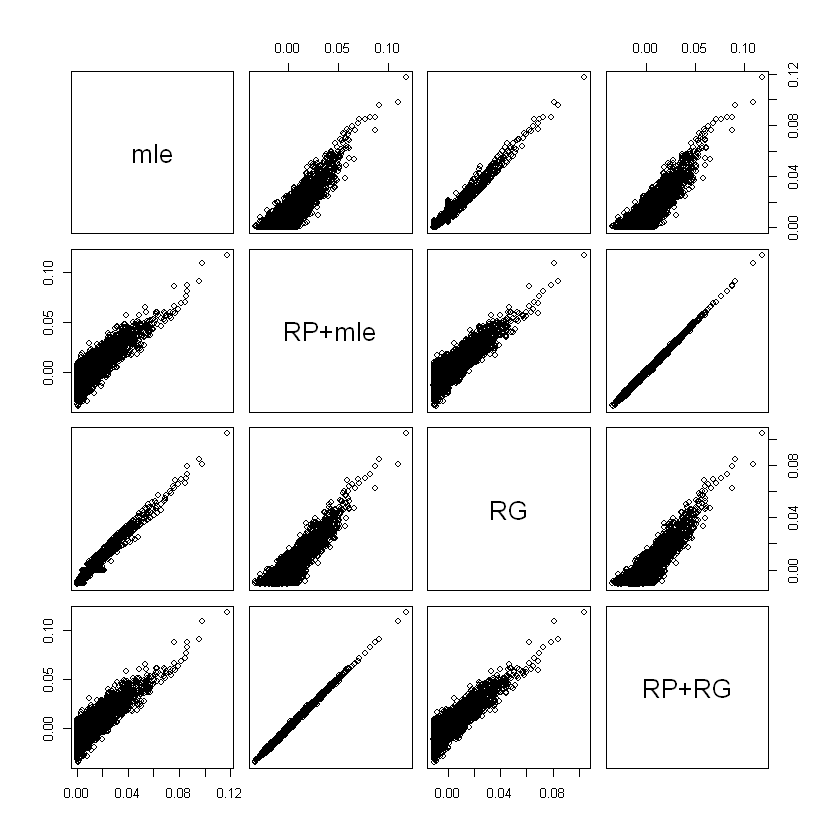

In [21]:
# PAIRWISE SCATTER PLOTS
pairs(data.frame(y$r2_mle, y$r2_mle_block, y$r2_RG, y$r2_RG_block), labels=c('mle', 'RP+mle', 'RG', 'RP+RG'))

In [7]:
dyn.unload('../cpp/unbiased_r2_2.dll')